In [1]:
%pip install econml dowhy

   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ------------------ --------------------- 1.0/2.3 MB 5.6 MB/s eta 0:00:01
   ------------------ --------------------- 1.0/2.3 MB 5.6 MB/s eta 0:00:01
   ---------------------- ----------------- 1.3/2.3 MB 1.9 MB/s eta 0:00:01
   ---------------------------------------- 2.3/2.3 MB 2.8 MB/s  0:00:00
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------------------------------------- -- 1.3/1.4 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 5.3 MB/s  0:00:00
   ---------------------------------------- 0.0/41.2 MB ? eta -:--:--
   -- ------------------------------------- 2.9/41.2 MB 14.0 MB/s eta 0:00:03
   ---- ----------------------------------- 4.5/41.2 MB 10.8 MB/s eta 0:00:04
   ------ --------------------------------- 6.8/41.2 MB 11.7 MB/s eta 0:00:03
   --------- ------------------------------ 10.2/41.2 MB 12.3 MB/s eta 0:00:03
   ------------ -------------

In [2]:
import pandas as pd

df = pd.read_csv("../data/raw_customer_data.csv")

df.head()

,customer_id,age,past_purchases,product_views,website_visits,avg_order_value,days_since_last_purchase,loyalty_score,cart_additions,email_engagement,customer_tenure,product_interest_score,previous_discount_usage,discount,purchase
0,C000001,26,0,4,7,1629.17,34,69,7,25,21,60,1,0,1
1,C000002,57,2,13,14,2006.95,44,8,3,31,51,87,3,20,1
2,C000003,62,4,10,8,2408.13,120,67,3,80,51,44,0,20,0
3,C000004,47,3,8,9,1433.72,134,20,4,31,9,87,1,0,0
4,C000005,65,3,12,10,1935.84,134,55,3,3,53,78,4,0,0


In [3]:
features = [
    "age",
    "past_purchases",
    "product_views",
    "website_visits",
    "avg_order_value",
    "days_since_last_purchase",
    "loyalty_score",
    "cart_additions",
    "email_engagement",
    "customer_tenure",
    "product_interest_score",
    "previous_discount_usage"
]

X = df[features]
T = df["discount"]
Y = df["purchase"]

X.shape, T.shape, Y.shape

((100000, 12), (100000,), (100000,))

In [4]:
import dowhy

causal_graph = """
digraph {
    age -> purchase;
    past_purchases -> purchase;
    product_views -> purchase;
    website_visits -> purchase;
    avg_order_value -> purchase;
    days_since_last_purchase -> purchase;
    loyalty_score -> purchase;
    cart_additions -> purchase;
    email_engagement -> purchase;
    customer_tenure -> purchase;
    product_interest_score -> purchase;
    previous_discount_usage -> purchase;

    discount -> purchase;
}
"""

print(causal_graph)

c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



digraph {
    age -> purchase;
    past_purchases -> purchase;
    product_views -> purchase;
    website_visits -> purchase;
    avg_order_value -> purchase;
    days_since_last_purchase -> purchase;
    loyalty_score -> purchase;
    cart_additions -> purchase;
    email_engagement -> purchase;
    customer_tenure -> purchase;
    product_interest_score -> purchase;
    previous_discount_usage -> purchase;

    discount -> purchase;
}



In [5]:
from dowhy import CausalModel

model = CausalModel(
    data=df,
    treatment="discount",
    outcome="purchase",
    graph=causal_graph
)

model

In [6]:
identified_estimand = model.identify_effect()

print(identified_estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                  
───────────(E[purchase])
d[discount]             
Estimand assumption 1, Unconfoundedness: If U→{discount} and U→purchase then P(purchase|discount,,U) = P(purchase|discount,)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
     d                  
───────────(E[purchase])
d[discount]             
Estimand assumption 1, Unconfoundedness: If U→{discount} and U→purchase then P(purchase|discount,,U) = P(purchase|discount,)



In [7]:
T_binary = (df["discount"] > 0).astype(int)

T_binary.value_counts()

discount
1    60144
0    39856
Name: count, dtype: int64

In [10]:
from econml.dml import LinearDML
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

model_dml = LinearDML(
    model_y=RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    model_t=RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    discrete_treatment=True,
    random_state=42
)

In [11]:
model_dml.fit(Y, T_binary, X=X)

In [12]:
ite = model_dml.effect(X)

ite[:10]

array([0.20056419, 0.19248765, 0.16651929, 0.22391232, 0.18710796,
       0.21420046, 0.18247932, 0.13163185, 0.17025232, 0.17666724])

In [13]:
ite.mean(), ite.min(), ite.max()

In [14]:
df["ite_any_discount"] = ite

df[["customer_id", "discount", "purchase", "ite_any_discount"]].head(10)

,customer_id,discount,purchase,ite_any_discount
0,C000001,0,1,0.200564
1,C000002,20,1,0.192488
2,C000003,20,0,0.166519
3,C000004,0,0,0.223912
4,C000005,0,0,0.187108
5,C000006,0,1,0.214200
6,C000007,10,1,0.182479
7,C000008,20,0,0.131632
8,C000009,20,0,0.170252
9,C000010,20,1,0.176667


In [15]:
top_persuadable = df[
    ["customer_id", "discount", "purchase", "ite_any_discount"]
].sort_values(
    "ite_any_discount",
    ascending=False
).head(10)

top_persuadable

,customer_id,discount,purchase,ite_any_discount
20019,C020020,0,0,0.269947
98019,C098020,10,0,0.268013
72944,C072945,10,0,0.266053
58288,C058289,0,0,0.264989
74881,C074882,10,1,0.263388
5828,C005829,10,1,0.262304
45939,C045940,20,1,0.262073
76243,C076244,10,1,0.261443
26953,C026954,20,0,0.261008
67619,C067620,20,1,0.260015


In [16]:
df["discount"].value_counts().sort_index()

discount
0     39856
10    30138
20    30006
Name: count, dtype: int64

In [17]:
df_10_0 = df[df["discount"].isin([0, 10])].copy()

T_10_0 = (df_10_0["discount"] == 10).astype(int)
X_10_0 = df_10_0[features]
Y_10_0 = df_10_0["purchase"]

model_dml_10_0 = LinearDML(
    model_y=RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    model_t=RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    discrete_treatment=True,
    random_state=42
)

model_dml_10_0.fit(Y_10_0, T_10_0, X=X_10_0)

ite_10_0 = model_dml_10_0.effect(X_10_0)

df_10_0["ite_10_vs_0"] = ite_10_0

df_10_0[["customer_id", "discount", "purchase", "ite_10_vs_0"]].head(10)

,customer_id,discount,purchase,ite_10_vs_0
0,C000001,0,1,0.155859
3,C000004,0,0,0.176439
4,C000005,0,0,0.145344
5,C000006,0,1,0.180324
6,C000007,10,1,0.129579
12,C000013,0,1,0.162120
13,C000014,10,0,0.097494
15,C000016,0,0,0.116849
17,C000018,10,1,0.118447
18,C000019,10,1,0.158955


In [18]:
df_20_0 = df[df["discount"].isin([0, 20])].copy()

T_20_0 = (df_20_0["discount"] == 20).astype(int)
X_20_0 = df_20_0[features]
Y_20_0 = df_20_0["purchase"]

model_dml_20_0 = LinearDML(
    model_y=RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    model_t=RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        random_state=42
    ),
    discrete_treatment=True,
    random_state=42
)

model_dml_20_0.fit(Y_20_0, T_20_0, X=X_20_0)

ite_20_0 = model_dml_20_0.effect(X_20_0)

df_20_0["ite_20_vs_0"] = ite_20_0

df_20_0[["customer_id", "discount", "purchase", "ite_20_vs_0"]].head(10)

,customer_id,discount,purchase,ite_20_vs_0
0,C000001,0,1,0.238025
1,C000002,20,1,0.239115
2,C000003,20,0,0.219859
3,C000004,0,0,0.271122
4,C000005,0,0,0.231394
5,C000006,0,1,0.244036
7,C000008,20,0,0.178140
8,C000009,20,0,0.236691
9,C000010,20,1,0.241372
10,C000011,20,0,0.208896


In [19]:
comparison = df_10_0[["customer_id", "ite_10_vs_0"]].merge(
    df_20_0[["customer_id", "ite_20_vs_0"]],
    on="customer_id"
)

comparison["best_discount"] = comparison.apply(
    lambda row: 20 if row["ite_20_vs_0"] > row["ite_10_vs_0"] else 10,
    axis=1
)

comparison.head(10)


,customer_id,ite_10_vs_0,ite_20_vs_0,best_discount
0,C000001,0.155859,0.238025,20
1,C000004,0.176439,0.271122,20
2,C000005,0.145344,0.231394,20
3,C000006,0.180324,0.244036,20
4,C000013,0.162120,0.278918,20
5,C000016,0.116849,0.227633,20
6,C000020,0.126585,0.219854,20
7,C000021,0.136119,0.236840,20
8,C000025,0.167472,0.251156,20
9,C000026,0.153698,0.245634,20


In [20]:
comparison["best_discount"].value_counts()

best_discount
20    39856
Name: count, dtype: int64

In [21]:
comparison.shape

In [22]:
comparison_all = pd.DataFrame({
    "customer_id": df["customer_id"],
    "ite_10_vs_0": model_dml_10_0.effect(df[features]),
    "ite_20_vs_0": model_dml_20_0.effect(df[features])
})

comparison_all["best_discount"] = comparison_all.apply(
    lambda row: 20 if row["ite_20_vs_0"] > row["ite_10_vs_0"] else 10,
    axis=1
)

comparison_all.head(10)

,customer_id,ite_10_vs_0,ite_20_vs_0,best_discount
0,C000001,0.155859,0.238025,20
1,C000002,0.145967,0.239115,20
2,C000003,0.123608,0.219859,20
3,C000004,0.176439,0.271122,20
4,C000005,0.145344,0.231394,20
5,C000006,0.180324,0.244036,20
6,C000007,0.129579,0.227669,20
7,C000008,0.090395,0.178140,20
8,C000009,0.105378,0.236691,20
9,C000010,0.118367,0.241372,20


In [23]:
comparison_all["best_discount"].value_counts()

best_discount
20    100000
Name: count, dtype: int64

In [24]:
comparison_all["incremental_effect_20_vs_10"] = (
    comparison_all["ite_20_vs_0"]
    - comparison_all["ite_10_vs_0"]
)

comparison_all.head(10)

,customer_id,ite_10_vs_0,ite_20_vs_0,best_discount,incremental_effect_20_vs_10
0,C000001,0.155859,0.238025,20,0.082166
1,C000002,0.145967,0.239115,20,0.093147
2,C000003,0.123608,0.219859,20,0.096251
3,C000004,0.176439,0.271122,20,0.094684
4,C000005,0.145344,0.231394,20,0.086051
5,C000006,0.180324,0.244036,20,0.063712
6,C000007,0.129579,0.227669,20,0.098090
7,C000008,0.090395,0.178140,20,0.087745
8,C000009,0.105378,0.236691,20,0.131313
9,C000010,0.118367,0.241372,20,0.123005


In [25]:
comparison_all["incremental_effect_20_vs_10"].describe()

count    100000.000000
mean          0.089250
std           0.021258
min           0.010772
25%           0.074090
50%           0.089127
75%           0.104431
max           0.162833
Name: incremental_effect_20_vs_10, dtype: float64

In [26]:
df.columns.tolist()


['customer_id',
 'age',
 'past_purchases',
 'product_views',
 'website_visits',
 'avg_order_value',
 'days_since_last_purchase',
 'loyalty_score',
 'cart_additions',
 'email_engagement',
 'customer_tenure',
 'product_interest_score',
 'previous_discount_usage',
 'discount',
 'purchase',
 'ite_any_discount']

In [27]:
comparison_all["additional_expected_revenue"] = (
    comparison_all["incremental_effect_20_vs_10"]
    * df["avg_order_value"].values
)

comparison_all[
    ["customer_id", "incremental_effect_20_vs_10", "additional_expected_revenue"]
].head(10)

,customer_id,incremental_effect_20_vs_10,additional_expected_revenue
0,C000001,0.082166,133.862950
1,C000002,0.093147,186.941936
2,C000003,0.096251,231.784377
3,C000004,0.094684,135.749731
4,C000005,0.086051,166.580023
5,C000006,0.063712,80.865858
6,C000007,0.098090,195.861910
7,C000008,0.087745,180.033813
8,C000009,0.131313,289.810317
9,C000010,0.123005,242.936863


In [28]:
comparison_all["estimated_net_value_20_vs_10"] = (
    comparison_all["additional_expected_revenue"] - 10
)

comparison_all[
    [
        "customer_id",
        "incremental_effect_20_vs_10",
        "additional_expected_revenue",
        "estimated_net_value_20_vs_10"
    ]
].head(10)

,customer_id,incremental_effect_20_vs_10,additional_expected_revenue,estimated_net_value_20_vs_10
0,C000001,0.082166,133.862950,123.862950
1,C000002,0.093147,186.941936,176.941936
2,C000003,0.096251,231.784377,221.784377
3,C000004,0.094684,135.749731,125.749731
4,C000005,0.086051,166.580023,156.580023
5,C000006,0.063712,80.865858,70.865858
6,C000007,0.098090,195.861910,185.861910
7,C000008,0.087745,180.033813,170.033813
8,C000009,0.131313,289.810317,279.810317
9,C000010,0.123005,242.936863,232.936863


In [29]:
comparison_all["estimated_net_value_20_vs_10"].describe()

count    100000.000000
mean        125.134516
std          58.512079
min          -5.343897
25%          82.970710
50%         119.190314
75%         161.218809
max         450.363888
Name: estimated_net_value_20_vs_10, dtype: float64

In [30]:
(comparison_all["estimated_net_value_20_vs_10"] > 0).value_counts()

estimated_net_value_20_vs_10
True     99965
False       35
Name: count, dtype: int64

In [31]:
policy_df = comparison_all.copy()

policy_df["avg_order_value"] = df["avg_order_value"].values

policy_df["recommended_discount"] = policy_df["estimated_net_value_20_vs_10"].apply(
    lambda x: 20 if x > 0 else 10
)

policy_df = policy_df[
    [
        "customer_id",
        "ite_10_vs_0",
        "ite_20_vs_0",
        "incremental_effect_20_vs_10",
        "avg_order_value",
        "estimated_net_value_20_vs_10",
        "recommended_discount"
    ]
]

policy_df.head(10)

,customer_id,ite_10_vs_0,ite_20_vs_0,incremental_effect_20_vs_10,avg_order_value,estimated_net_value_20_vs_10,recommended_discount
0,C000001,0.155859,0.238025,0.082166,1629.17,123.862950,20
1,C000002,0.145967,0.239115,0.093147,2006.95,176.941936,20
2,C000003,0.123608,0.219859,0.096251,2408.13,221.784377,20
3,C000004,0.176439,0.271122,0.094684,1433.72,125.749731,20
4,C000005,0.145344,0.231394,0.086051,1935.84,156.580023,20
5,C000006,0.180324,0.244036,0.063712,1269.24,70.865858,20
6,C000007,0.129579,0.227669,0.098090,1996.76,185.861910,20
7,C000008,0.090395,0.178140,0.087745,2051.79,170.033813,20
8,C000009,0.105378,0.236691,0.131313,2207.02,279.810317,20
9,C000010,0.118367,0.241372,0.123005,1975.01,232.936863,20


In [32]:
persuadables = policy_df.sort_values(
    "incremental_effect_20_vs_10",
    ascending=False
).head(20)

persuadables

,customer_id,ite_10_vs_0,ite_20_vs_0,incremental_effect_20_vs_10,avg_order_value,estimated_net_value_20_vs_10,recommended_discount
11901,C011902,0.107553,0.270386,0.162833,2348.54,372.419823,20
53550,C053551,0.110863,0.272551,0.161687,2481.95,391.299965,20
95759,C095760,0.106712,0.265527,0.158815,2560.05,396.573951,20
91231,C091232,0.118678,0.276596,0.157918,2010.56,307.503359,20
79497,C079498,0.123746,0.279547,0.155801,1753.95,263.267546,20
3112,C003113,0.106473,0.261957,0.155484,2054.69,309.470547,20
4321,C004322,0.117447,0.272671,0.155224,1539.37,228.946670,20
40014,C040015,0.118006,0.273196,0.155189,2120.46,319.073051,20
35920,C035921,0.097033,0.251800,0.154767,1979.89,296.421701,20
8200,C008201,0.109299,0.263757,0.154457,1772.77,263.817379,20


In [33]:
df["true_treatment_effect_10"] = (
    0.002 * df["product_interest_score"]
    + 0.001 * df["loyalty_score"]
    + 0.003 * df["cart_additions"]
)

df[
    [
        "customer_id",
        "true_treatment_effect_10"
    ]
].head(10)

,customer_id,true_treatment_effect_10
0,C000001,0.210
1,C000002,0.191
2,C000003,0.164
3,C000004,0.206
4,C000005,0.220
5,C000006,0.244
6,C000007,0.135
7,C000008,0.101
8,C000009,0.025
9,C000010,0.063


In [34]:
validation = pd.DataFrame({
    "customer_id": df["customer_id"],
    "true_effect_10": df["true_treatment_effect_10"],
    "dml_effect_10": model_dml_10_0.effect(df[features])
})

validation["absolute_error"] = (
    validation["true_effect_10"] - validation["dml_effect_10"]
).abs()

validation.head(10)

,customer_id,true_effect_10,dml_effect_10,absolute_error
0,C000001,0.210,0.155859,0.054141
1,C000002,0.191,0.145967,0.045033
2,C000003,0.164,0.123608,0.040392
3,C000004,0.206,0.176439,0.029561
4,C000005,0.220,0.145344,0.074656
5,C000006,0.244,0.180324,0.063676
6,C000007,0.135,0.129579,0.005421
7,C000008,0.101,0.090395,0.010605
8,C000009,0.025,0.105378,0.080378
9,C000010,0.063,0.118367,0.055367


In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(
    validation["true_effect_10"],
    validation["dml_effect_10"]
)

rmse = mean_squared_error(
    validation["true_effect_10"],
    validation["dml_effect_10"]
) ** 0.5

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 0.0432561665590465
RMSE: 0.0530349459865699


In [36]:
correlation = validation[
    ["true_effect_10", "dml_effect_10"]
].corr().iloc[0, 1]

print("Correlation between true and DML effects:", correlation)

Correlation between true and DML effects: 0.7900551970456815


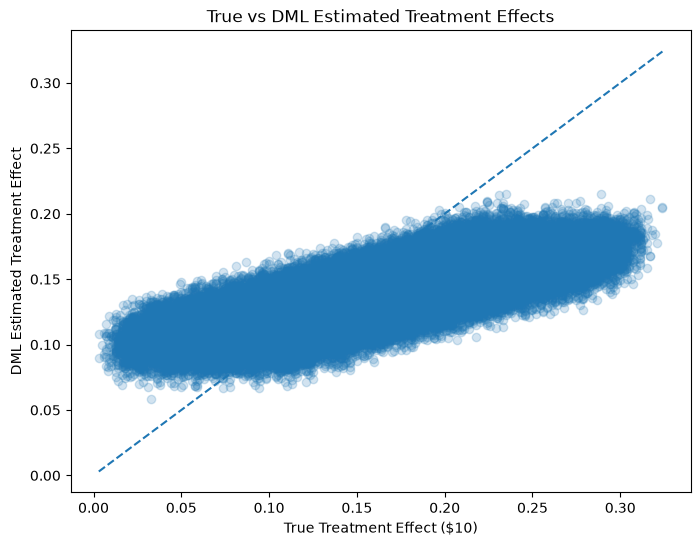

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    validation["true_effect_10"],
    validation["dml_effect_10"],
    alpha=0.2
)

plt.xlabel("True Treatment Effect ($10)")
plt.ylabel("DML Estimated Treatment Effect")
plt.title("True vs DML Estimated Treatment Effects")

# Perfect-estimation reference line
min_val = min(
    validation["true_effect_10"].min(),
    validation["dml_effect_10"].min()
)
max_val = max(
    validation["true_effect_10"].max(),
    validation["dml_effect_10"].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.show()